### Importações e função de plotagem

In [104]:
import random
import timeit
import matplotlib.pyplot as plt

In [105]:
def plotar_comparacao(dados_grafico, titulo="Comparação de Desempenho"):
    plt.figure(figsize=(8, 5))
    for config in dados_grafico:
        plt.scatter(config['eixo_x'], config['tempos'], color=config['cor'], label=config['label'])
    
    plt.xlabel("Tamanho da Lista")
    plt.ylabel("Tempo Médio (s)")
    plt.title(titulo)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

# Exercícios - Algoritmo de Ordenação - Parte II


## Exercício Prático 1
Implementar o algoritmo merge sort abaixo


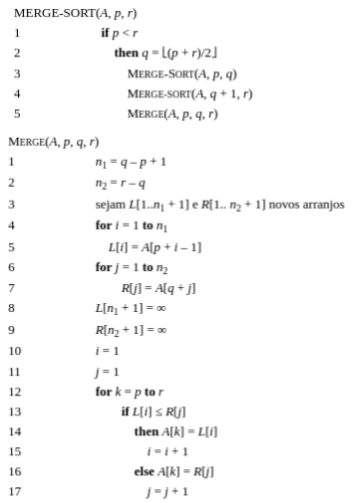

Testar para ordenar em ordem crescente listas geradas conforme abaixo:

    min_val = 10
    max_val = 100
    L = []
    for tamanho in range(5, 20, 5):
      L.append([random.randint(min_val, max_val) for _ in range(tamanho)])

    for lista in L:
      print("Lista original:", lista)
      merge_sort(lista)
      print("Lista ordenada:", lista)
      print("-" * 20)

##Solução

In [106]:
def merge_sort(L):
    if len(L) <= 1:
        return L
    metade = len(L) // 2
    esquerda = merge_sort(L[:metade])
    direita = merge_sort(L[metade:])
    return merge(esquerda, direita)

def merge(esquerda, direita):
    l_aux = []
    i =  j = 0
    while i < len(esquerda) and j < len(direita):
        if esquerda[i] <= direita[j]:
            l_aux.append(esquerda[i])
            i += 1
        else:
            l_aux.append(direita[j])
            j += 1
    l_aux.extend(esquerda[i:])
    l_aux.extend(direita[j:])
    return l_aux
    

In [126]:
min_val = 10
max_val = 100
L = []
for tamanho in range(5, 20, 5):
    L.append([random.randint(min_val, max_val) for _ in range(tamanho)])


In [127]:
for lista in L:
    print("Lista original:", lista)
    ordenada = merge_sort(lista)
    print("Lista ordenada:", ordenada)
    print("-" * 20)

Lista original: [24, 36, 70, 81, 13]
Lista ordenada: [13, 24, 36, 70, 81]
--------------------
Lista original: [35, 13, 15, 87, 19, 13, 31, 99, 30, 76]
Lista ordenada: [13, 13, 15, 19, 30, 31, 35, 76, 87, 99]
--------------------
Lista original: [84, 46, 10, 42, 78, 88, 50, 25, 82, 80, 98, 94, 98, 51, 87]
Lista ordenada: [10, 25, 42, 46, 50, 51, 78, 80, 82, 84, 87, 88, 94, 98, 98]
--------------------


#Exercício Prático 2

Repetir os testes do Exercício Prático 1 para a implementação do algoritmo quick sort abaixo:

        Quicksort(L, p, r)
        if (p < r)
          q = Partition(L, p, r)
          Quicksort(L, p, q)
          Quicksort(L, q+1, r)



        Particao(L,p,r)//pivô=primeiro
        valor = L[p]
        i = p
        Para j = p+1 até r faça
          Se L[j] ≤ valor
            i = i + 1
            troca(L[i],L[j])
        troca(L[i],L[p])
        retorna  i


##Solução

In [109]:
def quicksort(L, low=0, high=None):
    if high is None:
        high = len(L)-1
    if low < high:
        p = particao(L, low, high)
        quicksort(L, low, p-1)
        quicksort(L, p+1, high)
    return L
    
        
def particao(L,low, high):
    i=low
    pivot = L[high]
    for j in range(low, high):
        if L[j] > pivot:
            L[i], L[j] = L[j], L[i]
            i += 1
    L[i], L[high] = L[high], L[i]
    return i
            
    
    


In [128]:
min_val = 10
max_val = 100
L = []
for tamanho in range(5, 20, 5):
    L.append([random.randint(min_val, max_val) for _ in range(tamanho)])


for lista in L:
    print("Lista original:", lista)
    ordenada = quicksort(lista)
    print("Lista ordenada:", ordenada)
    print("-" * 20)

Lista original: [99, 57, 24, 81, 49]
Lista ordenada: [99, 81, 57, 49, 24]
--------------------
Lista original: [53, 34, 57, 40, 50, 68, 15, 15, 54, 71]
Lista ordenada: [71, 68, 57, 54, 53, 50, 40, 34, 15, 15]
--------------------
Lista original: [90, 16, 86, 35, 41, 25, 16, 28, 16, 84, 82, 26, 87, 71, 18]
Lista ordenada: [90, 87, 86, 84, 82, 71, 41, 35, 28, 26, 25, 18, 16, 16, 16]
--------------------


---

In [111]:
# GERADOR DE LISTAS CRESCENTES E DECRESCENTES

min_val = 1
max_val = 100

L_cresc = []
L_decresc = []


for tamanho in range(10, 101, 10): 

    for repetição in range(10):
        
        lista_aleatoria = [random.randint(min_val, max_val) for _ in range(tamanho)]
        
        lista_aleatoria_cresc = sorted(lista_aleatoria)
        lista_aleatoria_decresc = sorted(lista_aleatoria, reverse=True)
        
        L_cresc.append(lista_aleatoria_cresc)
        L_decresc.append(lista_aleatoria_decresc)

#Exercício Prático 3

Plote gráficos comparando o desempenho do algoritmo bubble_sort  para ordenar em ordem crescente, considerando dois casos distintos: listas já ordenadas e  listas ordenadas em ordem inversa. Nos dois casos,  as listas geradas devem ter tamanho variando de 10  a 100. Utilize 10 repetições para o cálculo do tempo médio.


##Solução

In [112]:
def bubble_sort_otimizado(L):
    n = len(L)
    for i in range(n):
        troca = False
        for j in range(0, n - i - 1):
            if L[j] > L[j + 1]: 
                L[j], L[j + 1] = L[j + 1], L[j]
                troca = True
        if not troca:
            break          
    return L


In [113]:
bs_cresc_tempo = []
eixo_x_c = []

for i in L_cresc:
    bs_cresc = timeit.Timer(lambda: bubble_sort_otimizado(i.copy()))
    tempo_medio = bs_cresc.timeit(number=10) / 10
    bs_cresc_tempo.append(tempo_medio)
    eixo_x_c.append(len(i))


In [114]:
bs_decresc_tempo = []
eixo_x_d = []

for i in L_decresc:
    bs_decresc = timeit.Timer(lambda: bubble_sort_otimizado(i.copy()))
    tempo_medio = bs_decresc.timeit(number=10) / 10 
    bs_decresc_tempo.append(tempo_medio)
    eixo_x_d.append(len(i))


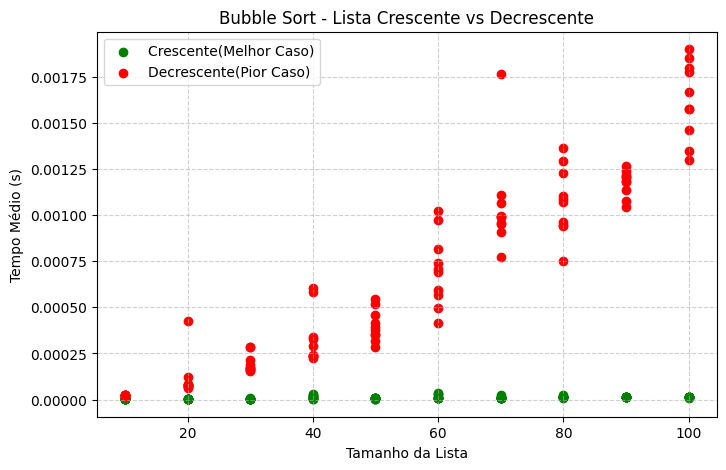

In [115]:
dados_para_plotar = [
    {'eixo_x': eixo_x_c, 'tempos': bs_cresc_tempo, 'cor': 'green', 'label': 'Crescente(Melhor Caso)'},
    {'eixo_x': eixo_x_d, 'tempos': bs_decresc_tempo, 'cor': 'red', 'label': 'Decrescente(Pior Caso)'}
]

plotar_comparacao(dados_para_plotar, "Bubble Sort - Lista Crescente vs Decrescente")

#Exercício Prático 4
Repetir a análise da atividade prática 1 anterior  para o algoritmo insertion sort e selection sort, considerando apenas listas ordenadas, plotando o gráfico dos dois algoritmos.

##Solução

In [116]:
def insertion_sort(L):
    n = len(L)
    for j in range(1, n):
        chave = L[j]
        i = j - 1
        while i >= 0 and L[i] > chave:
            L[i+1] = L[i]
            i -= 1
        L[i+1] = chave 
    return L


In [117]:
def selection_sort(L):
    n = len(L)
    for i in range(n):
        min_idx = i
        for j in range(i+1, n):
            if L[j] < L[min_idx]:
                min_idx = j
        L[i], L[min_idx] = L[min_idx], L[i]
    return L


In [118]:
tempos_insertion = []
tempos_selection = []
eixo_x = []

for sublista in L_cresc:
    t_ins = timeit.Timer(lambda: insertion_sort(sublista.copy())).timeit(number=10) / 10
    t_sel = timeit.Timer(lambda: selection_sort(sublista.copy())).timeit(number=10) / 10
    
    tempos_insertion.append(t_ins)
    tempos_selection.append(t_sel)
    eixo_x.append(len(sublista))



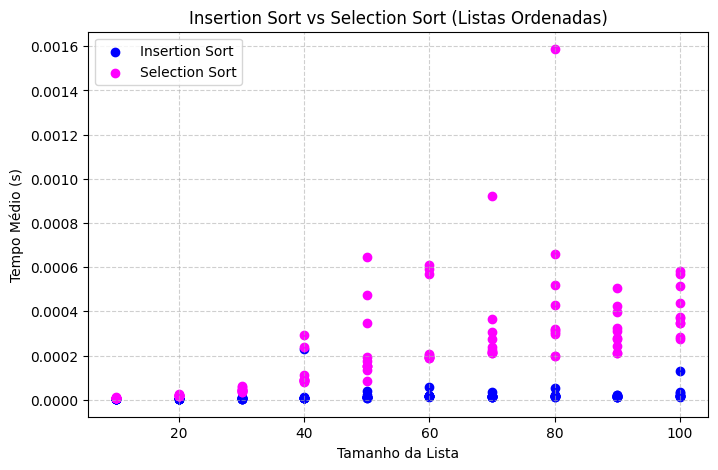

In [119]:
dados_para_plotar = [
    {'eixo_x': eixo_x, 'tempos': tempos_insertion, 'cor': 'blue', 'label': 'Insertion Sort'},
    {'eixo_x': eixo_x, 'tempos': tempos_selection, 'cor': 'magenta', 'label': 'Selection Sort'}
]

plotar_comparacao(dados_para_plotar, "Insertion Sort vs Selection Sort (Listas Ordenadas)")

#Exercício Prático 5

Repetir a análise da atividade prática 1 anterior para o algoritmo insertion sort e selection sort, considerando apenas listas ordenadas em ordem inversa, plotando o gráfico dos dois algoritmos.

##Solução

In [120]:
tempos_insertion = []
tempos_selection = []
eixo_x = []

L_decresc = [sorted(sublista, reverse=True) for sublista in L_cresc]

In [121]:
for sublista in L_decresc:
    t_ins = timeit.Timer(lambda: merge_sort(sublista.copy())).timeit(number=10) / 10
    t_sel = timeit.Timer(lambda: quicksort(sublista.copy())).timeit(number=10) / 10
    
    tempos_insertion.append(t_ins)
    tempos_selection.append(t_sel)
    eixo_x.append(len(sublista))

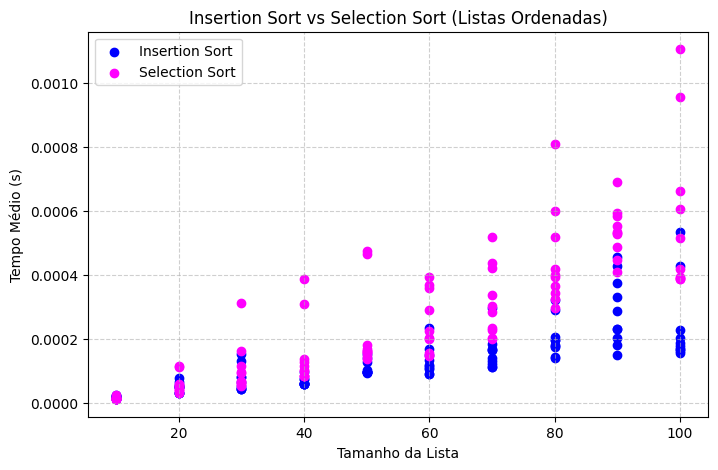

In [122]:
dados_para_plotar = [
    {'eixo_x': eixo_x, 'tempos': tempos_insertion, 'cor': 'blue', 'label': 'Insertion Sort'},
    {'eixo_x': eixo_x, 'tempos': tempos_selection, 'cor': 'magenta', 'label': 'Selection Sort'}
]

plotar_comparacao(dados_para_plotar, "Insertion Sort vs Selection Sort (Listas Ordenadas)")

#Exercício Prático 6

Repetir a análise anterior para o algoritmo merge e quick sort, considerando apenas listas ordenadas,  plotando o gráfico dos dois algoritmos



##Solução

In [123]:
tempos_merge = []
tempos_quick = []
eixo_x = []

In [124]:
#Função Merge Sort aproveitada do exercício 1
#Função Quick Sort aproveitada do exercício 2
#L_cresc reaproveitada do exercício x

for sublista in L_cresc:
    t_ins = timeit.Timer(lambda: merge_sort(sublista.copy())).timeit(number=10) / 10
    t_sel = timeit.Timer(lambda: quicksort(sublista.copy())).timeit(number=10) / 10
    
    tempos_merge.append(t_ins)
    tempos_quick.append(t_sel)
    eixo_x.append(len(sublista))


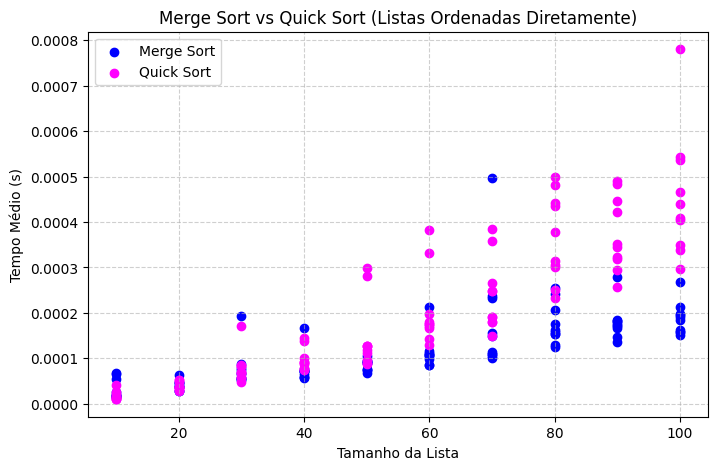

In [125]:

dados_para_plotar = [
    {'eixo_x': eixo_x, 'tempos': tempos_merge, 'cor': 'blue', 'label': 'Merge Sort'},
    {'eixo_x': eixo_x, 'tempos': tempos_quick, 'cor': 'magenta', 'label': 'Quick Sort'}
]

plotar_comparacao(dados_para_plotar, "Merge Sort vs Quick Sort (Listas Ordenadas Diretamente)")

#Exercício Prático 7

Repetir a análise anterior para o algoritmo merge e quick sort, considerando apenas listas ordenadas em ordem inversa, plotando o gráfico dos dois algoritmos



##Solução

In [129]:
tempos_merge = []
tempos_quick = []
eixo_x = []

In [130]:
#Função Merge Sort aproveitada do exercício 1
#Função Quick Sort aproveitada do exercício 2
#L_cresc reaproveitada do exercício x

for sublista in L_decresc:
    t_ins = timeit.Timer(lambda: merge_sort(sublista.copy())).timeit(number=10) / 10
    t_sel = timeit.Timer(lambda: quicksort(sublista.copy())).timeit(number=10) / 10
    
    tempos_merge.append(t_ins)
    tempos_quick.append(t_sel)
    eixo_x.append(len(sublista))


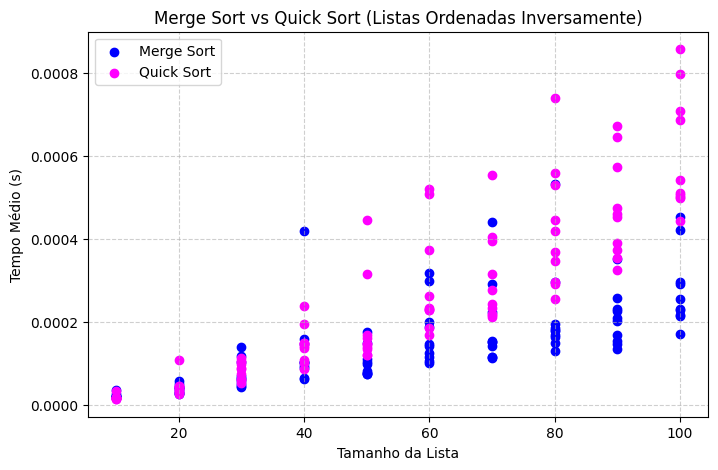

In [132]:
dados_para_plotar = [
    {'eixo_x': eixo_x, 'tempos': tempos_merge, 'cor': 'blue', 'label': 'Merge Sort'},
    {'eixo_x': eixo_x, 'tempos': tempos_quick, 'cor': 'magenta', 'label': 'Quick Sort'}
]

plotar_comparacao(dados_para_plotar, "Merge Sort vs Quick Sort (Listas Ordenadas Inversamente)")